# Laporan Praktikum Sistem Pengolahan Digital

**Nama:** Adi Suryadi  
**NIM:**  607022400039  
**Mata Kuliah:** Sistem Pengolahan Digital
**Modul: Modul4**: Rekonstruksi Sinyal

## Soal 1
Diberikan sinyal:

$$x(t)=\sin(20\pi t)+\sin(50\pi t)$$

Sinyal ini memiliki dua komponen frekuensi, yaitu **10 Hz** dan **25 Hz**.
Akan diamati spektrum saat disampling dengan:
- $f_s = 100$ Hz
- $f_s = 25$ Hz

Jumlah sampel awal      : 16000
Jumlah sampel downsample: 8000
Durasi awal             : 2.00 s
Durasi downsample (play di 8 kHz): 1.00 s


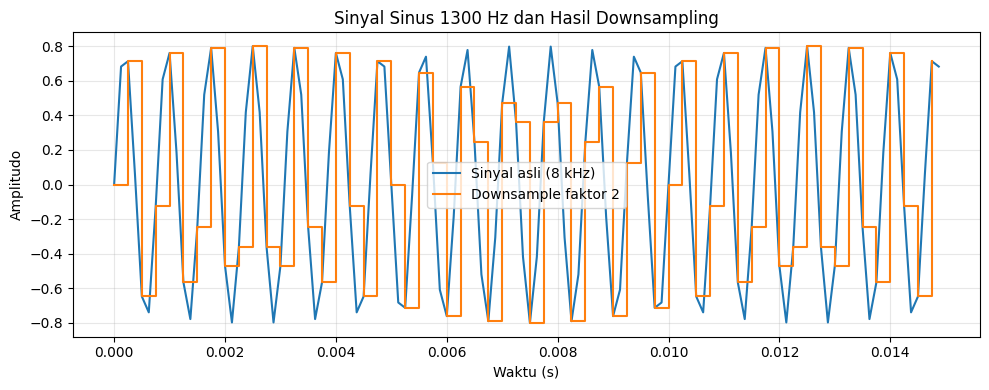

### Dengarkan sinyal asli (fs = 8 kHz)

### Dengarkan sinyal setelah downsampling faktor 2 (diputar di fs = 8 kHz)

Komentar: Setelah downsampling faktor 2 dan diputar pada fs yang sama (8 kHz), suara terdengar lebih tinggi (sekitar naik 1 oktaf, dari 1300 Hz ke 2600 Hz) serta durasinya menjadi lebih pendek (setengah durasi awal).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown

# Parameter sinyal
f0 = 1300          # frekuensi dasar (Hz)
fs = 8000          # frekuensi sampling (Hz)
durasi = 2.0       # detik

# Bangkitkan sinyal sinusoidal
n = np.arange(int(fs * durasi))
t = n / fs
x = 0.8 * np.sin(2 * np.pi * f0 * t)

# Downsampling faktor 2
M = 2
x_down = x[::M]

# Untuk demonstrasi efek downsampling pada pendengaran,
# sinyal downsample diputar kembali dengan fs asli 8 kHz.
# Akibatnya durasi menjadi setengah dan pitch terdengar lebih tinggi.

print(f"Jumlah sampel awal      : {len(x)}")
print(f"Jumlah sampel downsample: {len(x_down)}")
print(f"Durasi awal             : {len(x)/fs:.2f} s")
print(f"Durasi downsample (play di 8 kHz): {len(x_down)/fs:.2f} s")

# Visualisasi sebagian sinyal
N_show = 120
plt.figure(figsize=(10, 4))
plt.plot(t[:N_show], x[:N_show], label='Sinyal asli (8 kHz)')
plt.step(t[:N_show:M], x_down[:N_show//M], where='post', label='Downsample faktor 2', linewidth=1.5)
plt.title('Sinyal Sinus 1300 Hz dan Hasil Downsampling')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Audio playback
display(Markdown('### Dengarkan sinyal asli (fs = 8 kHz)'))
display(Audio(x, rate=fs))

display(Markdown('### Dengarkan sinyal setelah downsampling faktor 2 (diputar di fs = 8 kHz)'))
display(Audio(x_down, rate=fs))

# Komentar hasil
display(Markdown(
    'Komentar: Setelah downsampling faktor 2 dan diputar pada fs yang sama (8 kHz), '
    'suara terdengar lebih tinggi (sekitar naik 1 oktaf, dari 1300 Hz ke 2600 Hz) '
    'serta durasinya menjadi lebih pendek (setengah durasi awal).'
))

### Kode 1 - Sinyal 1300 Hz dan Downsampling Faktor 2

**Keterangan grafik (sederhana):**
- Garis biru menunjukkan sinyal sinus asli pada fs = 8 kHz.
- Garis tangga oranye menunjukkan sinyal setelah downsampling faktor 2.
- Setelah downsampling, jumlah sampel berkurang sehingga representasi waktunya lebih jarang.

**Catatan audio:**
- Saat sinyal hasil downsampling diputar pada fs yang sama, suara terdengar lebih tinggi dan durasinya lebih pendek.

fs = 100 Hz -> frekuensi dominan (perkiraan): [ 6. 10. 17. 25. 44.]
fs = 25 Hz -> frekuensi dominan (perkiraan): [ 0.  3.  6.  8. 10.]


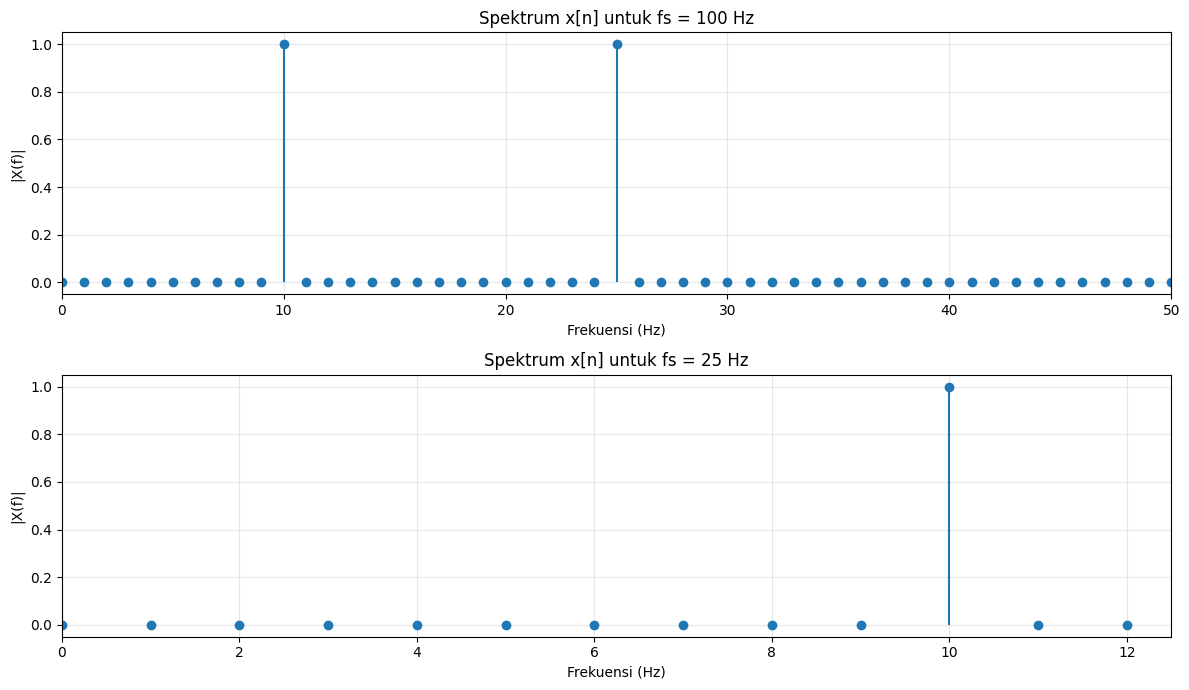

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Definisi sinyal kontinu: x(t) = sin(20*pi*t) + sin(50*pi*t)
# Komponen frekuensi: 10 Hz dan 25 Hz

def sampled_signal(fs, duration=1.0):
    t = np.arange(0, duration, 1/fs)
    x = np.sin(20*np.pi*t) + np.sin(50*np.pi*t)
    return t, x

def single_sided_spectrum(x, fs):
    N = len(x)
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(N, d=1/fs)
    mag = (2.0 / N) * np.abs(X)
    return f, mag

fs_list = [100, 25]
duration = 1.0

plt.figure(figsize=(12, 7))

for i, fs in enumerate(fs_list):
    t, x = sampled_signal(fs, duration)
    f, mag = single_sided_spectrum(x, fs)

    # Plot spektrum
    plt.subplot(2, 1, i + 1)
    plt.stem(f, mag, basefmt=' ', linefmt='C0-', markerfmt='C0o')
    plt.title(f'Spektrum x[n] untuk fs = {fs} Hz')
    plt.xlabel('Frekuensi (Hz)')
    plt.ylabel('|X(f)|')
    plt.xlim(0, fs/2)
    plt.grid(alpha=0.3)

    # Tampilkan frekuensi dominan sederhana
    idx = np.argsort(mag)[-5:]
    dominant = np.sort(f[idx])
    print(f'fs = {fs} Hz -> frekuensi dominan (perkiraan): {np.round(dominant, 2)}')

plt.tight_layout()
plt.show()

### Kode 2 - Kuantisasi Mid-Rise (b = 1, 2, 4)

**Keterangan grafik (sederhana):**
- Subplot atas: kuantisasi 1-bit, bentuk tangga sangat kasar.
- Subplot tengah: kuantisasi 2-bit, bentuk tangga mulai mengikuti sinus.
- Subplot bawah: kuantisasi 4-bit, sinyal kuantisasi jauh lebih mendekati sinyal asli.

**Inti pengamatan:**
- Semakin besar bit-rate, semakin kecil error kuantisasi.

## Komentar Hasil Pengamatan

1. **Saat $f_s = 100$ Hz**
Spektrum menampilkan puncak yang sesuai dengan komponen asli sinyal, yaitu sekitar **10 Hz** dan **25 Hz**.
Ini karena laju sampling cukup tinggi, sehingga informasi frekuensi masih terwakili dengan baik.

2. **Saat $f_s = 25$ Hz**
Nyquist frequency menjadi $f_N = f_s/2 = 12.5$ Hz.
Komponen **25 Hz** berada di atas batas Nyquist, sehingga terlipat (alias) ke frekuensi yang lebih rendah.
Akibatnya, spektrum yang terlihat tidak sama dengan frekuensi asli sinyal.

3. **Kesimpulan singkat**
Aliasing terjadi ketika $f_s$ terlalu rendah terhadap kandungan frekuensi sinyal.
Untuk menghindari aliasing, gunakan syarat sampling Nyquist: $f_s > 2f_{max}$.

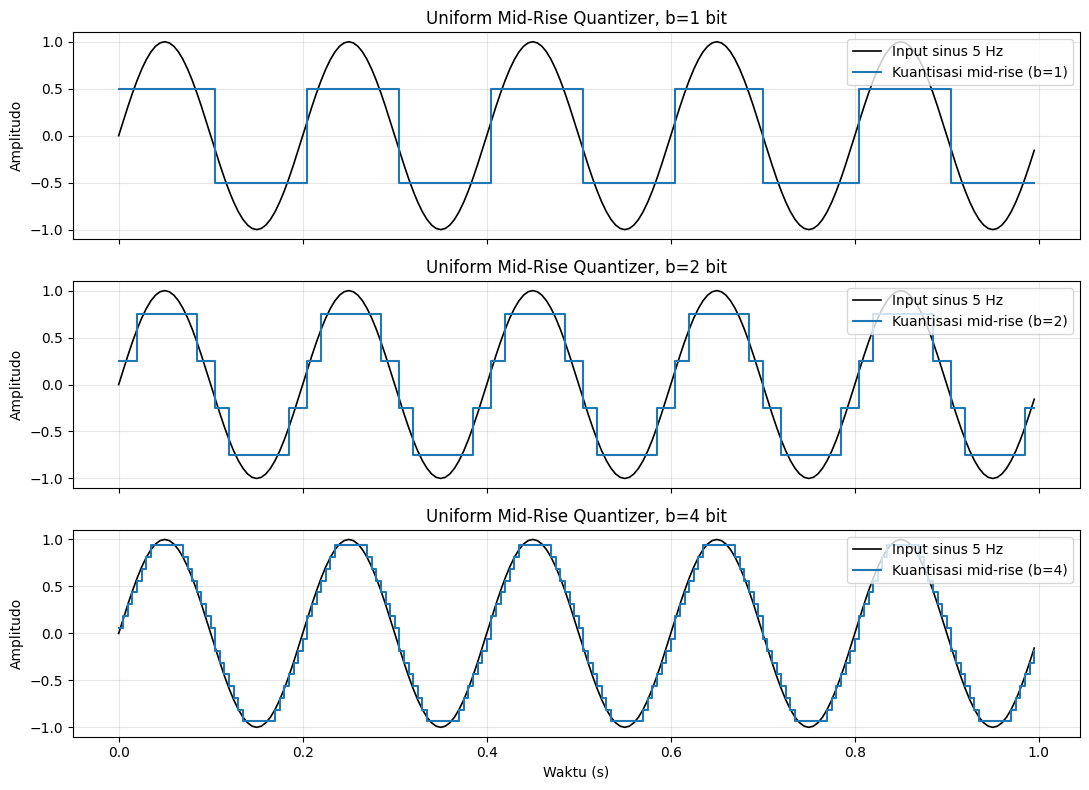

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter sinyal
fs = 200  # sampling frequency (Hz)
duration = 1.0  # durasi (detik)
f0 = 5  # frekuensi sinus (Hz)

t = np.arange(0, duration, 1 / fs)
x = np.sin(2 * np.pi * f0 * t)


def uniform_mid_rise_quantizer(x, b, xmin=-1.0, xmax=1.0):
    """Uniform mid-rise quantizer untuk b bit pada rentang [xmin, xmax]."""
    L = 2 ** b
    delta = (xmax - xmin) / L

    # Clip agar nilai tetap dalam rentang kuantisasi
    x_clip = np.clip(x, xmin, xmax - 1e-12)

    # Indeks level kuantisasi
    k = np.floor((x_clip - xmin) / delta)

    # Rekonstruksi level mid-rise: xmin + (k + 0.5) * delta
    xq = xmin + (k + 0.5) * delta
    return xq

bits = [1, 2, 4]

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

for ax, b in zip(axes, bits):
    xq = uniform_mid_rise_quantizer(x, b)

    ax.plot(t, x, 'k-', linewidth=1.2, label='Input sinus 5 Hz')
    ax.step(t, xq, where='post', linewidth=1.5, label=f'Kuantisasi mid-rise (b={b})')
    ax.set_ylabel('Amplitudo')
    ax.set_title(f'Uniform Mid-Rise Quantizer, b={b} bit')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

axes[-1].set_xlabel('Waktu (s)')
plt.tight_layout()
plt.show()

### Kode 3 - Verifikasi Aliasing pada fs = 8 Hz

**Keterangan grafik (sederhana):**
- Kurva biru adalah sinyal asli x(t).
- Kurva merah putus-putus adalah sinyal alias x'(t) = 3cos(2πt).
- Titik hitam adalah titik sampling pada fs = 8 Hz.

**Inti pengamatan:**
- Pada titik sampling, nilai kedua sinyal sama sehingga aliasing terbukti.

x[n] == x_alias[n] pada semua titik sampel: True


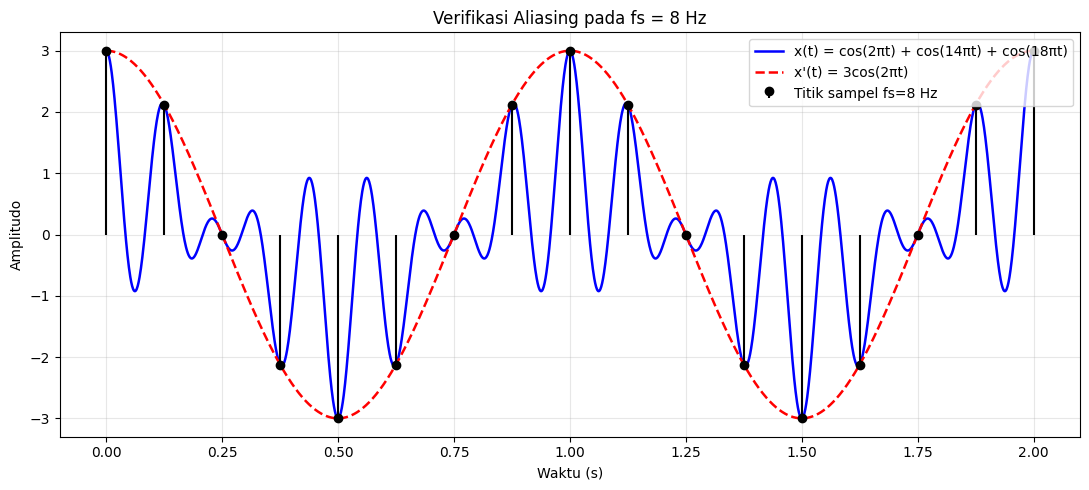

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Definisi sinyal analog
fs = 8  # Hz
f_base = 1  # karena cos(2πt) -> 1 Hz

t_cont = np.linspace(0, 2, 2000)  # waktu kontinu untuk visualisasi
x_t = np.cos(2 * np.pi * t_cont) + np.cos(14 * np.pi * t_cont) + np.cos(18 * np.pi * t_cont)
x_alias = 3 * np.cos(2 * np.pi * t_cont)

# Waktu sampling dan nilai sampel
t_s = np.arange(0, 2 + 1 / fs, 1 / fs)
x_s = np.cos(2 * np.pi * t_s) + np.cos(14 * np.pi * t_s) + np.cos(18 * np.pi * t_s)
x_alias_s = 3 * np.cos(2 * np.pi * t_s)

# Verifikasi numerik pada titik sampel
print('x[n] == x_alias[n] pada semua titik sampel:', np.allclose(x_s, x_alias_s))

# Plot kedua sinyal dan titik sampel
plt.figure(figsize=(11, 5))
plt.plot(t_cont, x_t, 'b', linewidth=1.8, label='x(t) = cos(2πt) + cos(14πt) + cos(18πt)')
plt.plot(t_cont, x_alias, 'r--', linewidth=1.8, label="x'(t) = 3cos(2πt)")

plt.stem(t_s, x_s, linefmt='k-', markerfmt='ko', basefmt=' ', label='Titik sampel fs=8 Hz')

plt.title('Verifikasi Aliasing pada fs = 8 Hz')
plt.xlabel('Waktu (s)')
plt.ylabel('Amplitudo')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

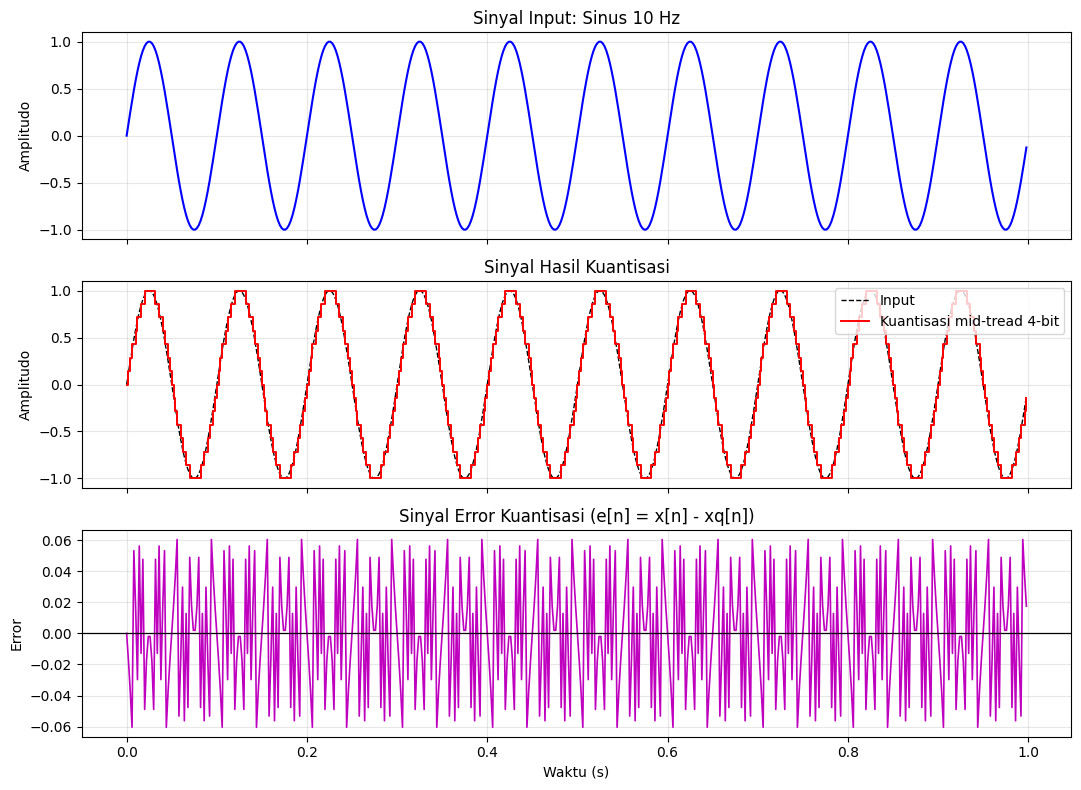

Step size (Δ)      : 0.142857
MSE error          : 0.001410
Maksimum |error|   : 0.060447


Komentar: Dengan kuantisasi uniform mid-tread 4-bit, sinyal keluaran berbentuk tangga dan masih cukup mengikuti sinus input. Error kuantisasi berosilasi di sekitar nol (rata-rata mendekati nol), dengan amplitudo relatif kecil. Distorsi tetap ada karena jumlah level kuantisasi terbatas, tetapi pada 4-bit kualitas bentuk sinyal sudah lebih baik dibanding bit yang lebih rendah.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Parameter sinyal
f0 = 10          # Hz
fs = 500         # Hz (cukup tinggi agar bentuk 10 Hz terlihat jelas)
duration = 1.0   # detik

t = np.arange(0, duration, 1 / fs)
x_in = np.sin(2 * np.pi * f0 * t)


def uniform_mid_tread_quantizer(x, b, xmax=1.0):
    """Uniform mid-tread quantizer b-bit (memiliki level nol)."""
    # Untuk b bit signed (dua's complement), indeks level: -2^(b-1) ... 2^(b-1)-1
    qmin = -(2 ** (b - 1))
    qmax = (2 ** (b - 1)) - 1

    # Step size berdasarkan rentang positif maksimum
    delta = xmax / qmax

    # Mid-tread: pembulatan ke level terdekat, sehingga ada dead-zone di sekitar nol
    q_index = np.round(x / delta)
    q_index = np.clip(q_index, qmin, qmax)
    x_q = q_index * delta
    return x_q, delta


b = 4
x_q, delta = uniform_mid_tread_quantizer(x_in, b=b, xmax=1.0)
err = x_in - x_q

# Statistik error
mse = np.mean(err ** 2)
max_err = np.max(np.abs(err))

# Plot: input, kuantisasi, error
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(t, x_in, 'b', linewidth=1.5)
axes[0].set_title('Sinyal Input: Sinus 10 Hz')
axes[0].set_ylabel('Amplitudo')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, x_in, 'k--', linewidth=1.0, label='Input')
axes[1].step(t, x_q, where='post', color='r', linewidth=1.4, label='Kuantisasi mid-tread 4-bit')
axes[1].set_title('Sinyal Hasil Kuantisasi')
axes[1].set_ylabel('Amplitudo')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

axes[2].plot(t, err, color='m', linewidth=1.2)
axes[2].axhline(0, color='k', linewidth=0.9)
axes[2].set_title('Sinyal Error Kuantisasi (e[n] = x[n] - xq[n])')
axes[2].set_xlabel('Waktu (s)')
axes[2].set_ylabel('Error')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Step size (Δ)      : {delta:.6f}")
print(f"MSE error          : {mse:.6f}")
print(f"Maksimum |error|   : {max_err:.6f}")

display(Markdown(
    "Komentar: Dengan kuantisasi uniform mid-tread 4-bit, sinyal keluaran berbentuk tangga "
    "dan masih cukup mengikuti sinus input. Error kuantisasi berosilasi di sekitar nol "
    "(rata-rata mendekati nol), dengan amplitudo relatif kecil. Distorsi tetap ada karena "
    "jumlah level kuantisasi terbatas, tetapi pada 4-bit kualitas bentuk sinyal sudah lebih baik "
    "dibanding bit yang lebih rendah."
))

### Kode 4 - Kuantisasi Mid-Tread 4-bit (10 Hz)

**Keterangan grafik (sederhana):**
- Grafik 1: sinyal input sinus 10 Hz.
- Grafik 2: sinyal hasil kuantisasi mid-tread 4-bit (bentuk tangga).
- Grafik 3: sinyal error kuantisasi e[n] = x[n] - xq[n].

**Inti pengamatan:**
- Error kuantisasi kecil dan berosilasi di sekitar nol, menandakan distorsi ada tetapi masih terkendali.

## Kesimpulan Pengerjaan

1. Proses sampling, kuantisasi, aliasing, dan downsampling berhasil disimulasikan dengan baik menggunakan Python.
2. Kuantisasi menunjukkan bahwa peningkatan jumlah bit membuat sinyal digital semakin mendekati sinyal analog.
3. Aliasing terbukti muncul ketika frekuensi sampling tidak cukup tinggi, sehingga sinyal berbeda dapat memiliki sampel yang sama.
4. Downsampling tanpa penyesuaian playback rate membuat durasi sinyal memendek dan nada terdengar lebih tinggi.
5. Secara umum, kualitas representasi sinyal digital sangat dipengaruhi oleh pemilihan frekuensi sampling dan resolusi kuantisasi.